# **Decision** **Tree** **Model**



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report,precision_score, recall_score,f1_score,roc_curve, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree


In [ ]:

#loading the csv file
from google.colab import files

uploaded=files.upload()
path=list(uploaded.keys())[0]
df = pd.read_csv(path)

Saving data_updated.csv to data_updated.csv


In [ ]:
#class distribution (count)
df["Target"].value_counts()

,count
Target,
Graduate,2209
Dropout,1421
Enrolled,794


In [ ]:
#class distribution for proportion

df["Target"].value_counts(normalize=True)

,proportion
Target,
Graduate,0.499322
Dropout,0.321203
Enrolled,0.179476


## **Data Preprocessing**

In [ ]:

X= df.drop(columns=['Target']) #represents the input varibles
y= df['Target'].replace({'Graduate':0, 'Dropout':1, 'Enrolled':2}) #represents the target variable

/tmp/ipykernel_919/2953359189.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y= df['Target'].replace({'Graduate':0, 'Dropout':1, 'Enrolled':2}) #represents the target variable


In [ ]:
#define categorical columns
categorical_cols = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]


## **One Hot Encoding**

In [ ]:
#do one hot encoding
from sklearn.preprocessing import OneHotEncoder

X_train_pre, X_test_pre, y_train, y_test=train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
    )

encoder=OneHotEncoder(sparse_output=False, handle_unknown='ignore')

X_train_encoded=encoder.fit_transform(X_train_pre[categorical_cols])
X_test_encoded=encoder.transform(X_test_pre[categorical_cols])


X_train_df=pd.DataFrame(X_train_encoded, columns=encoder.get_feature_names_out(categorical_cols))
X_test_df=pd.DataFrame(X_test_encoded, columns=encoder.get_feature_names_out(categorical_cols))

X_train_pre = X_train_pre.reset_index(drop=True)
X_test_pre = X_test_pre.reset_index(drop=True)

X_train_en=pd.concat([X_train_pre.drop(categorical_cols, axis=1), X_train_df],axis=1)
X_test_en=pd.concat([X_test_pre.drop(categorical_cols, axis=1), X_test_df],axis=1)




## **Balancing**

In [ ]:
#balancing
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

#undersampling
undersampler=RandomUnderSampler(sampling_strategy='auto', random_state=42)
X_resampled_under, y_resampled_under=undersampler.fit_resample(X_train_en,y_train)

#smote method
smote=SMOTE(sampling_strategy='auto', random_state=42)
X_resampled_smote, y_resampled_smote=smote.fit_resample(X_train_en, y_train)


## **Scaling and Normalization**

In [ ]:
#normalization and splitting data into training and testing

#imbalanced data
scaler= StandardScaler()
X_train=scaler.fit_transform(X_train_en)
X_test=scaler.transform(X_test_en)

#undersampled data
scaler_under= StandardScaler()
X_train_under=scaler_under.fit_transform(X_resampled_under)

#smote data
scaler_smote= StandardScaler()
X_train_smote=scaler_smote.fit_transform(X_resampled_smote)


# **Functions for the Descision Tree Model**

In [ ]:
#training decision tree using gini impurity

def train_using_gini(X_train, y_train):
    clf_gini = DecisionTreeClassifier(criterion="gini", random_state=100, max_depth=3, min_samples_leaf=5)
    clf_gini.fit(X_train, y_train)
    return clf_gini

In [ ]:
#training decision tree using entropy impurity

def train_using_entropy(X_train, y_train):
  clf_entropy = DecisionTreeClassifier(criterion="entropy", random_state=100, max_depth=3, min_samples_leaf=5)
  clf_entropy.fit(X_train, y_train)
  return clf_entropy

In [ ]:
#Make predictions

def predicition(X_test, clf_object):
  y_pred=clf_object.predict(X_test)
  print("Predicted values:\n", y_pred)
  return y_pred

In [ ]:
#Evaluating the model
def cal_accuracy(y_test, y_pred):
  print("\nConfusion Matrix:\n", confusion_matrix(y_test,y_pred))
  print("\nAccuracy:", accuracy_score(y_test,y_pred)*100)
  print("\nClassification Report:\n", classification_report(y_test, y_pred))

In [ ]:
#Comparision between Gini and Entropy Decision tree models


if __name__=="__main__":
  print("\n      Training Using Gini      ")
  clf_gini=train_using_gini(X_train, y_train)
  y_pred_gini=predicition(X_test, clf_gini)
  cal_accuracy(y_test, y_pred_gini)

  print("\n      Training Using Entropy      ")
  clf_entropy=train_using_entropy(X_train,y_train)
  y_pred_entropy=predicition(X_test, clf_entropy)
  cal_accuracy(y_test, y_pred_entropy)


      Training Using Gini      
Predicted values:
 [2 1 2 1 2 1 1 0 0 0 1 0 0 1 0 0 2 0 1 1 0 0 0 0 2 0 0 2 0 1 1 0 1 1 1 0 1
 1 0 0 0 1 1 1 0 1 0 0 0 1 1 2 2 0 0 1 0 1 0 0 0 1 1 1 0 1 1 0 0 0 1 1 0 1
 0 1 1 0 1 2 1 0 0 0 0 0 0 0 2 1 0 1 0 0 1 1 1 2 2 1 1 0 0 0 0 0 0 0 0 0 0
 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 1 1 0 0 0 0 1 2 1 0 0 0 1 1 1 2 0 0 0 1 0 0
 0 0 0 0 1 0 0 1 0 0 1 0 0 0 2 0 1 0 0 0 0 0 1 1 1 0 1 1 2 1 1 0 0 0 2 0 0
 0 0 2 0 0 1 2 2 0 2 1 0 1 1 1 1 2 2 0 0 0 0 0 2 0 1 0 2 1 0 0 1 2 0 0 1 1
 1 2 1 0 0 0 0 1 1 0 2 2 2 0 0 1 0 1 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 1 1 1
 0 2 2 0 0 1 0 1 0 0 2 2 2 1 0 1 0 1 1 0 0 1 0 2 0 2 0 2 0 1 0 2 0 0 1 2 0
 1 0 0 2 1 0 0 1 2 0 1 1 1 0 0 0 2 0 2 2 0 1 0 0 1 1 0 0 0 1 0 1 2 0 1 0 0
 0 0 1 0 1 2 1 0 0 2 0 0 0 0 0 2 0 0 0 1 1 1 1 1 0 1 1 0 0 1 0 0 1 0 2 1 2
 0 2 1 1 1 2 0 0 2 0 2 0 0 1 2 0 0 0 0 1 0 1 1 2 0 0 1 0 1 2 0 0 0 1 0 1 1
 1 2 0 1 0 2 1 1 0 2 0 0 0 0 0 0 1 0 1 1 0 0 2 2 0 0 2 1 0 0 2 2 0 2 1 0 0
 1 1 0 2 0 0 2 0 0 0 1 0 1 0 2 0 0 2 0 1 0 2 0 0

In [ ]:
#visualize decision tree
def plot_decison_tree(clf_object, feature_names, class_names):
  plt.figure(figsize=(30,20))
  plot_tree(clf_object, filled=True, feature_names=feature_names,
            class_names=class_names, rounded=True,
            max_depth=3, fontsize=14)
  plt.show()
  plt.close()




Gini Decision Tree


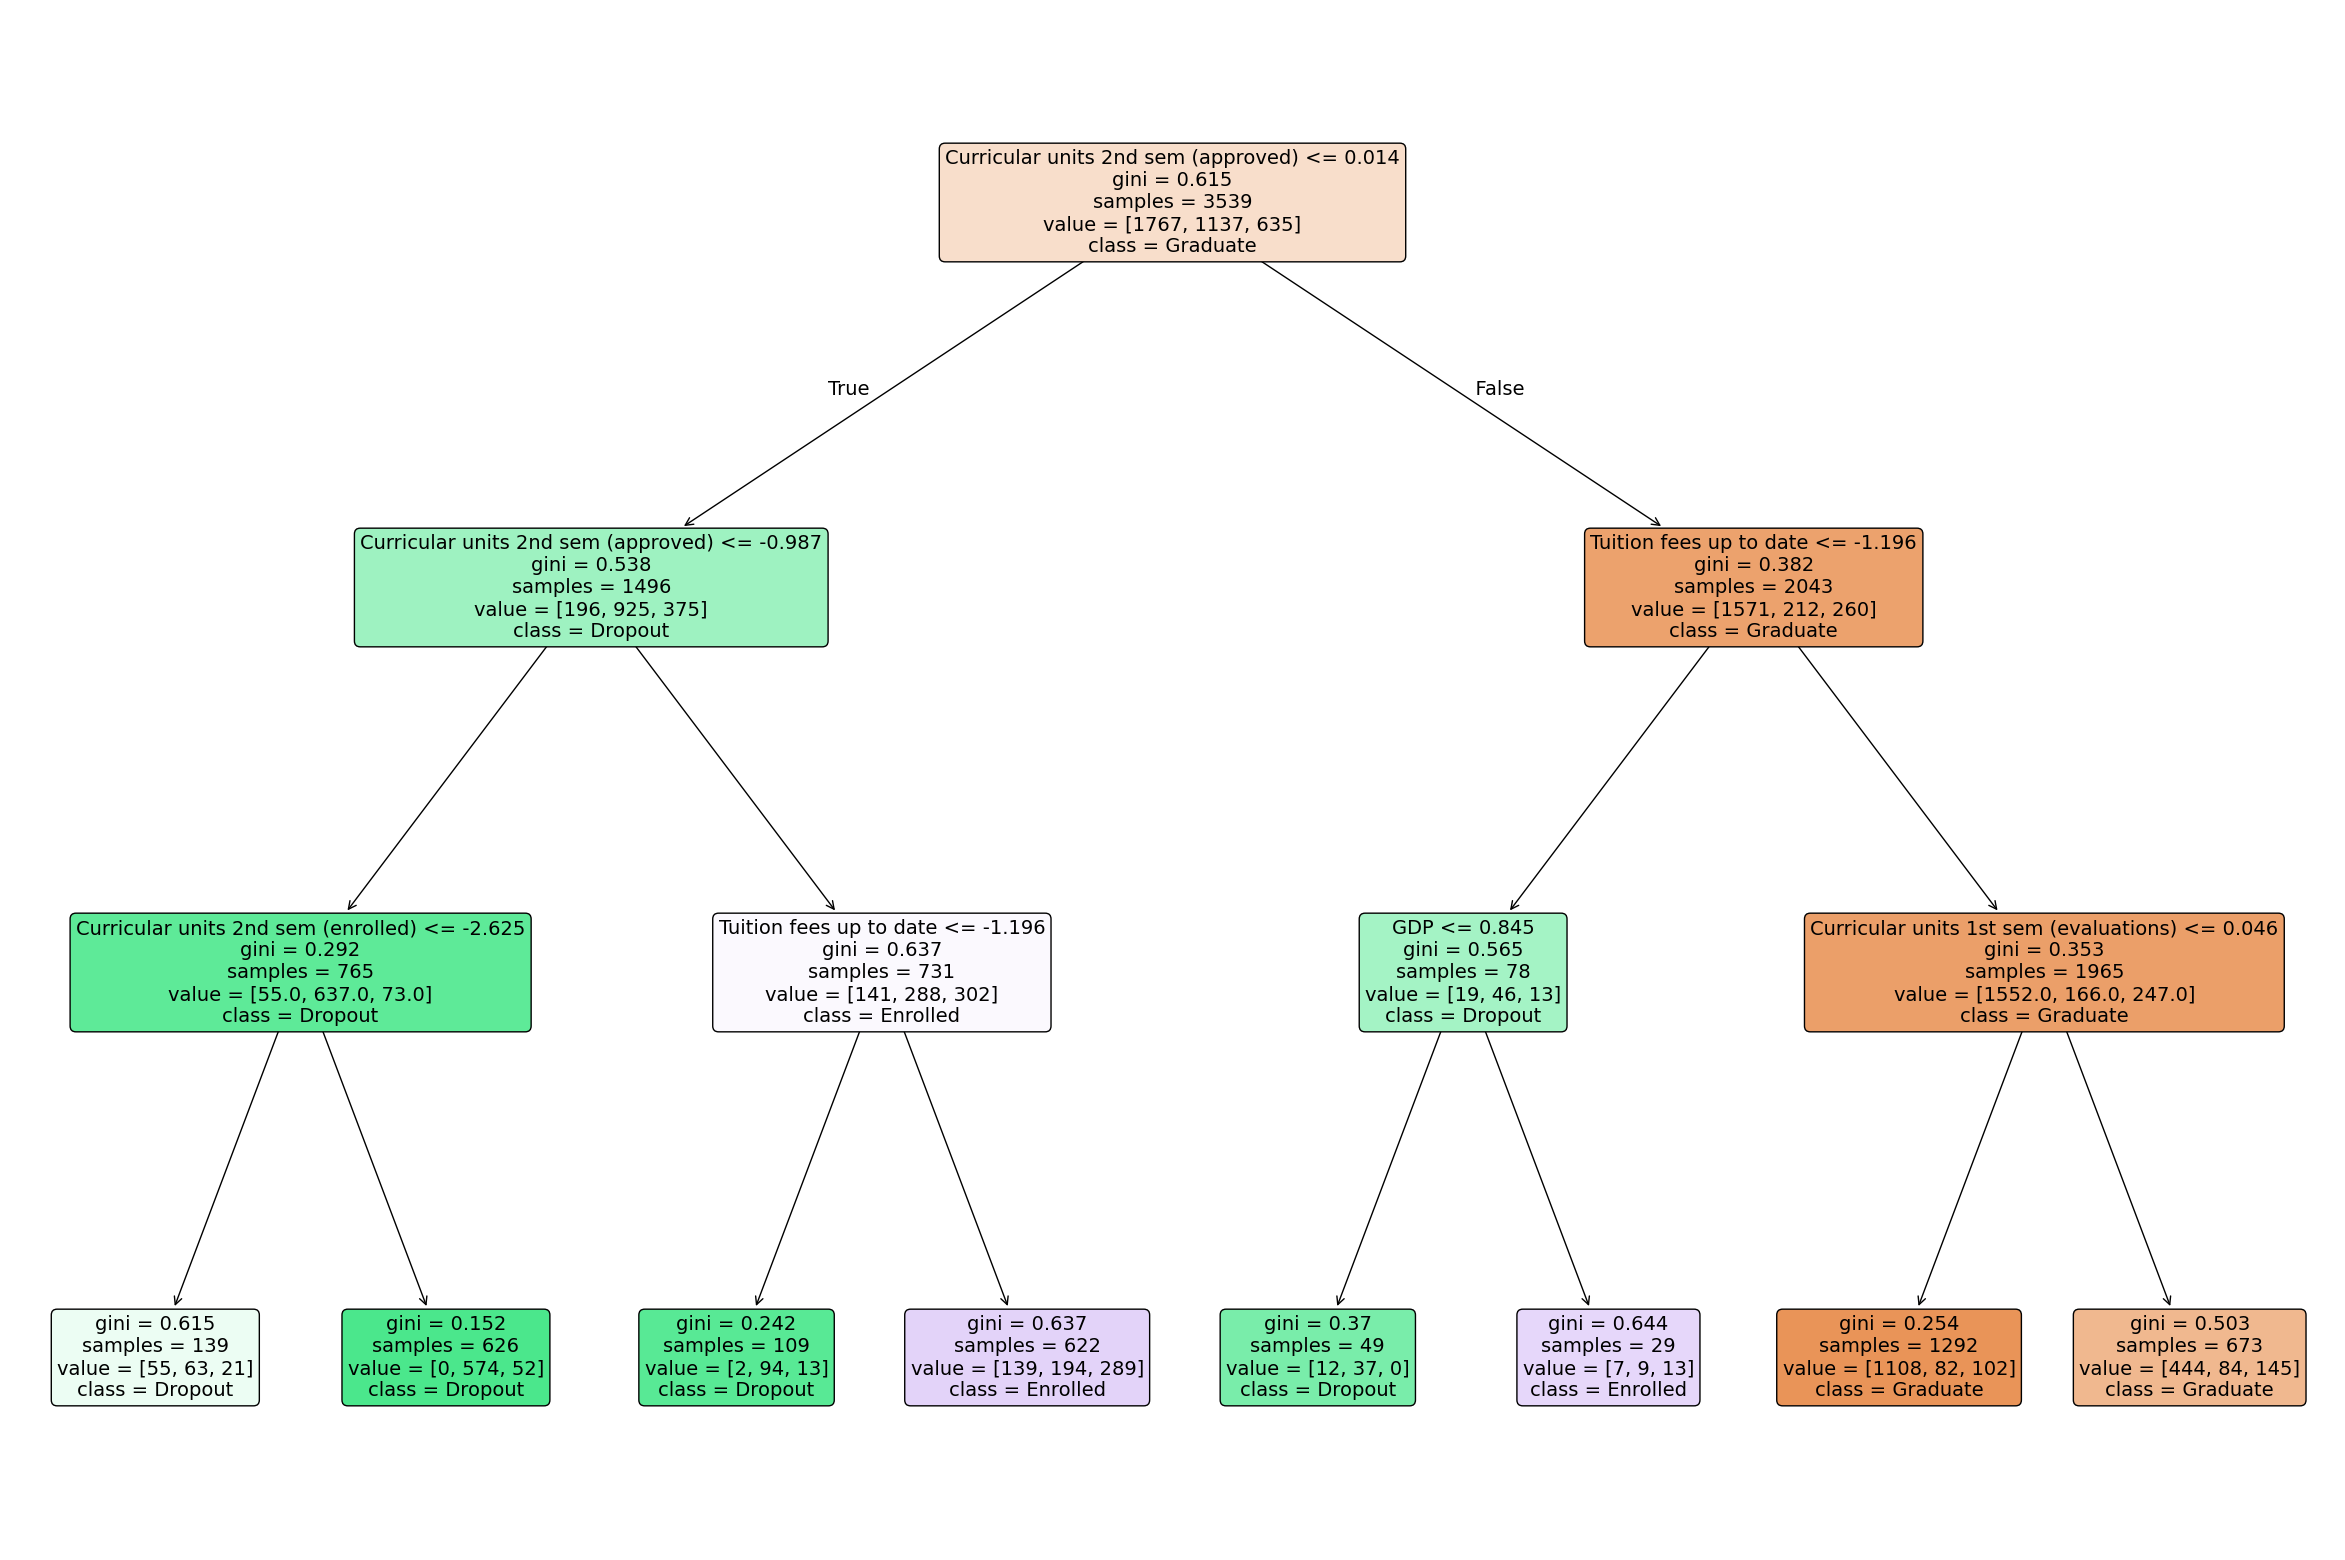

Entropy Decision Tree


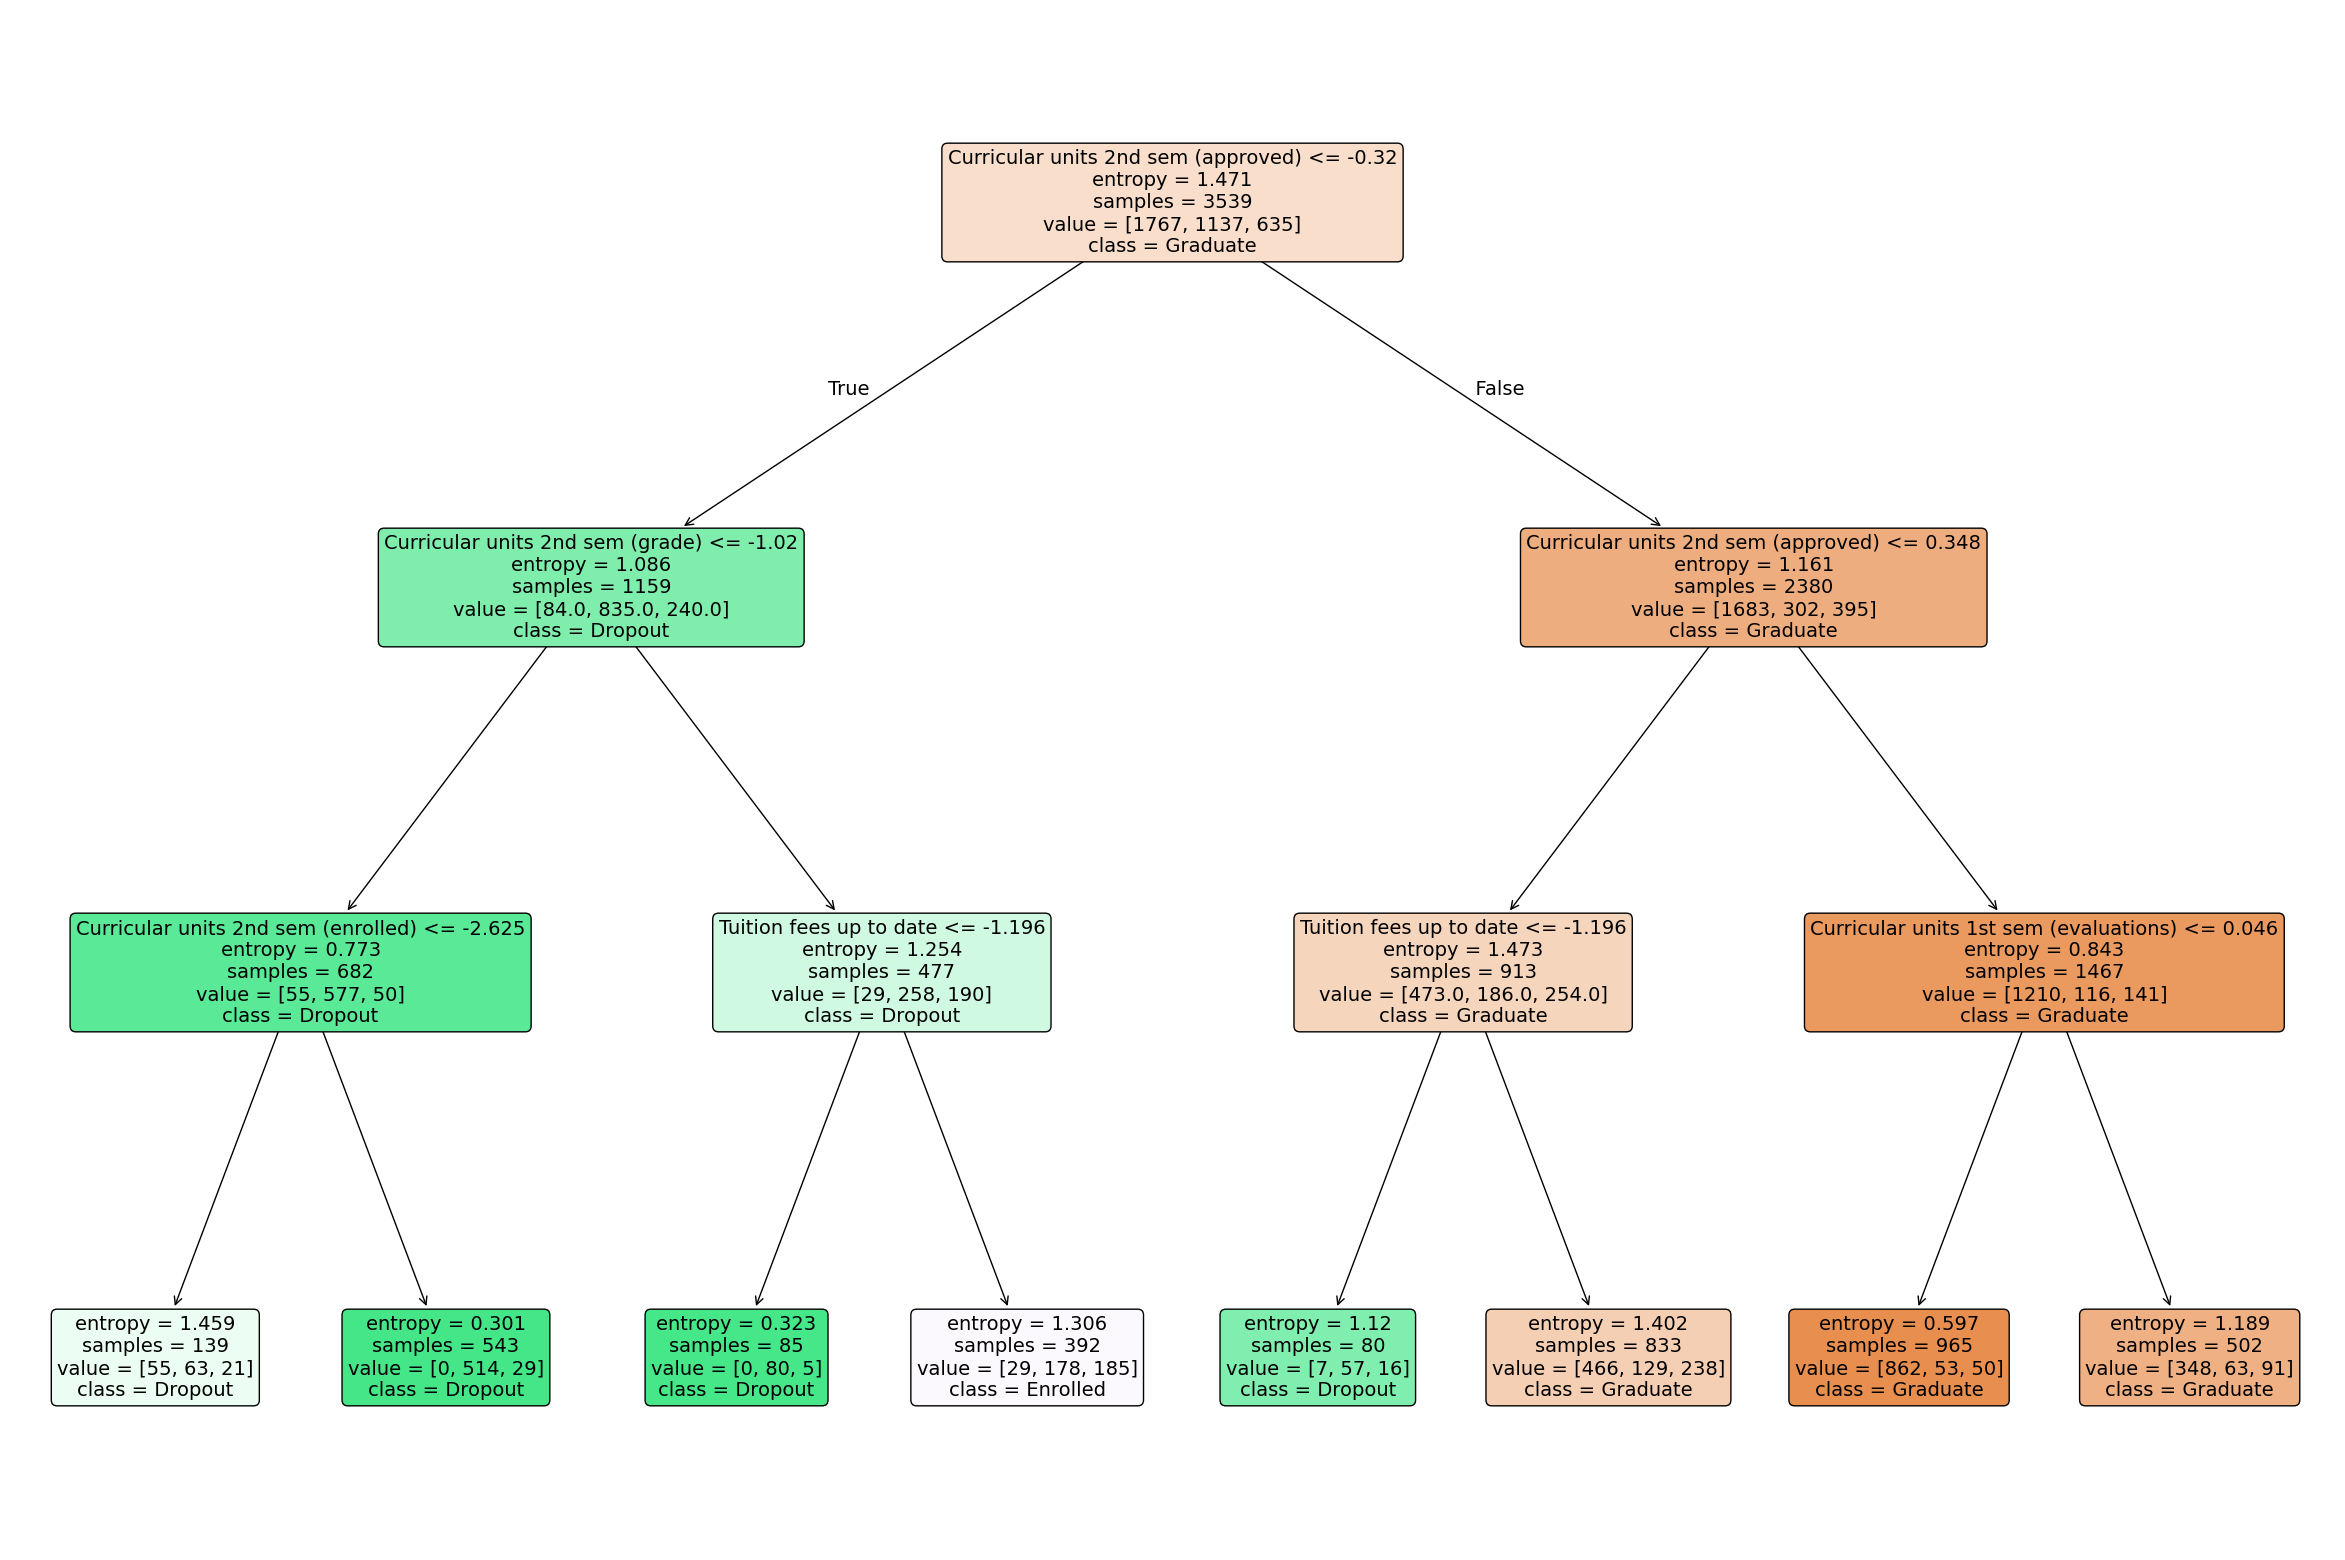

In [ ]:
feature_names= list(X_train_en.columns)
class_names=['Graduate', 'Dropout', 'Enrolled']
#visualizing Gini decision tree
print("Gini Decision Tree")
plot_decison_tree(clf_gini, feature_names, class_names)
#visualizing entropy decision tree
print("Entropy Decision Tree")
plot_decison_tree(clf_entropy, feature_names, class_names)

